In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from execution.schedules import compare_schedules

,ticker,shares,sector,price,adv20,vol20,spread20
0,RELIANCE.NS,3000000,Energy,1190.000000,15259242.15,0.016257,0.000100
1,TCS.NS,1000000,IT,2530.000000,5876698.45,0.021915,0.000100
2,HDFCBANK.NS,6000000,Banking,692.799988,31252108.50,0.015142,0.000886
3,INFY.NS,3000000,IT,1153.800049,14999728.20,0.022619,0.000100
4,ICICIBANK.NS,6000000,Banking,1394.199951,12517395.80,0.014024,0.004656


In [4]:
feats = pd.read_csv(r"C:\Users\Pc\PycharmProjects\Liquidity_Shock\data\features.csv", parse_dates=["date"])
port  = pd.read_csv(r"C:\Users\Pc\PycharmProjects\Liquidity_Shock\data\portfolio.csv")

In [5]:
latest = feats.sort_values("date").groupby("ticker").tail(1)
book = (port.merge(latest[["ticker", "close", "adv20", "vol20", "spread20"]], on="ticker")
            .rename(columns={"close": "price"}))
book.head()

,ticker,shares,sector,price,adv20,vol20,spread20
0,RELIANCE.NS,3000000,Energy,1190.000000,15259242.15,0.016257,0.000100
1,TCS.NS,1000000,IT,2530.000000,5876698.45,0.021915,0.000100
2,HDFCBANK.NS,6000000,Banking,692.799988,31252108.50,0.015142,0.000886
3,INFY.NS,3000000,IT,1153.800049,14999728.20,0.022619,0.000100
4,ICICIBANK.NS,6000000,Banking,1394.199951,12517395.80,0.014024,0.004656


TRIDENT.NS 80.0
                         days  total_cost  cost_bps  risk_bps  objective_bps  \
Immediate                 1.0  20602580.0     402.2       0.0          401.7   
At cap (fastest legal)   80.0   2326290.1      45.4     726.5          117.6   
TWAP                    160.0   1652364.6      32.3    1032.9          135.1   
VWAP                    160.0   1652364.6      32.3    1032.9          135.1   
Front-loaded            160.0   1863218.7      36.4     798.9          115.8   
Optimized               160.0   1972146.5      38.5     746.8          112.7   

                        peak_participation  within_cap  
Immediate                              8.0         0.0  
At cap (fastest legal)                 0.1         1.0  
TWAP                                   0.0         1.0  
VWAP                                   0.0         1.0  
Front-loaded                           0.1         1.0  
Optimized                              0.1         1.0  


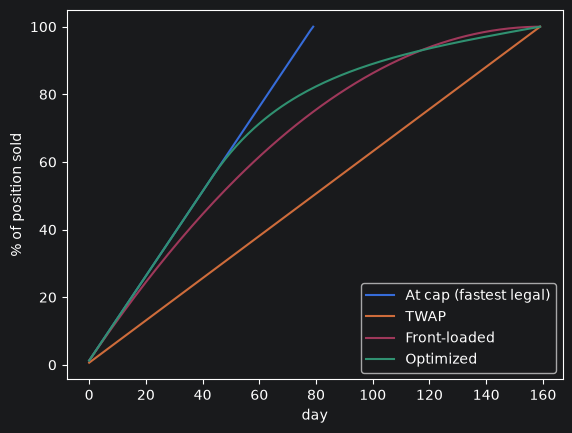

In [3]:
row = book.assign(days=np.ceil(book.shares / (0.10 * book.adv20))).sort_values("days").iloc[-1]
print(row.ticker, row.days)

tbl, plans = compare_schedules(S=row.shares, adv=row.adv20, sigma=row.vol20,
                               price=row.price, spread=row.spread20, p=0.10, lam=0.1)
print(tbl[["days", "total_cost", "cost_bps", "risk_bps", "objective_bps",
           "peak_participation", "within_cap"]].astype(float).round(1))

for name in ["At cap (fastest legal)", "TWAP", "Front-loaded", "Optimized"]:
    plt.plot(np.cumsum(plans[name]) / row.shares * 100, label=name)
plt.xlabel("day"); plt.ylabel("% of position sold"); plt.legend(); plt.show()

In [6]:
print(tbl[["days", "total_cost", "cost_bps", "risk_bps", "objective_bps",
           "peak_participation", "within_cap"]].astype(float).round(2).to_string())

                         days   total_cost  cost_bps  risk_bps  objective_bps  peak_participation  within_cap
Immediate                 1.0  20602580.00    402.20      0.00         401.70                7.99         0.0
At cap (fastest legal)   80.0   2326290.07     45.41    726.51         117.56                0.10         1.0
TWAP                    160.0   1652364.62     32.26   1032.94         135.05                0.05         1.0
VWAP                    160.0   1652364.62     32.26   1032.94         135.05                0.05         1.0
Front-loaded            160.0   1863218.67     36.37    798.87         115.76                0.10         1.0
Optimized               160.0   1972146.53     38.50    746.78         112.68                0.10         1.0


   lam  days  cost_bps  risk_bps
0  0.0   160      32.3    1032.9
1  0.0   160      33.9     863.1
2  0.0   160      36.6     774.2
3  0.1   160      38.5     746.8
4  0.2   160      40.2     734.7
5  0.5   160      41.9     728.8
6  1.0   160      42.9     727.4
7  2.0   149      43.5     726.9


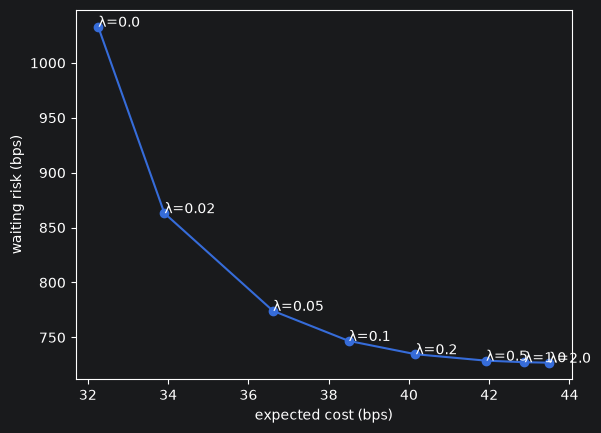

In [7]:
from execution.schedules import efficient_frontier

fr = efficient_frontier(S=row.shares, adv=row.adv20, sigma=row.vol20,
                        price=row.price, spread=row.spread20, p=0.10)
print(fr.round(1).to_string())

plt.plot(fr.cost_bps, fr.risk_bps, marker="o")
for _, r in fr.iterrows():
    plt.annotate(f"λ={r.lam}", (r.cost_bps, r.risk_bps))
plt.xlabel("expected cost (bps)")
plt.ylabel("waiting risk (bps)")
plt.show()

In [8]:
tbl.tail(3)

,days,spread_cost,impact_cost,total_cost,cost_bps,waiting_risk,risk_bps,objective_bps,peak_participation,within_cap
VWAP,160,25612.499714,1626752.116306,1652364.61602,32.256996,52912569.386539,1032.944265,135.051423,0.049939,True
Front-loaded,160,25612.499714,1837606.174026,1863218.67374,36.37323,40921874.786648,798.865305,115.75976,0.099258,True
Optimized,160,25612.499714,1946534.029716,1972146.52943,38.499689,38253827.031169,746.780429,112.677732,0.1,True
